# 💊 Forecasting de unidades - OTC Health Solutions (OTCHS)

## Integrantes:

- Juan Jose Campos Valderrama
- Miguel Delgado Arias 

## Nota sobre los datos

Los datos de este parcial provienen de una empresa farmacéutica estadounidense. Los identificadores de productos y centros de distribución fueron anonimizados, y su uso en este curso es exclusivamente académico.

---

## Contexto e introducción

Una compañía farmacéutica estadounidense comercializa un portafolio de productos de venta libre agrupado en el segmento **OTCHS (Over The Counter Health Solutions)**: analgésicos, antigripales, digestivos, vitaminas y otros productos de cuidado personal que el consumidor compra sin fórmula médica 💊. Estos productos se despachan semanalmente desde varios **centros de distribución (CD)** hacia farmacias y cadenas minoristas en todo el país 🚚.

El área de *Demand Planning* construye hoy sus pronósticos con reglas simples (promedios de las últimas semanas) y sus resultados se revisan **trimestralmente** en el comité de S&OP (*Sales & Operations Planning*). En ese comité los errores de pronóstico se convierten en sobrecostos de inventario o en quiebres de stock, y el negocio necesita reducirlos 📉.

La demanda de estos productos trae varios retos: estacionalidad (p. ej., temporada de gripa y alergias), picos asociados a los ciclos de pedido de los clientes, productos que entran o salen del portafolio, semanas sin pedidos y diferencias de volumen grandes entre centros de distribución. Por eso es indispensable hacer un análisis exploratorio cuidadoso antes de modelar 🧠.

## 🧩 Enunciado

Como consultor externo, se le solicita desarrollar un **modelo predictivo de unidades vendidas** para los SKUs del segmento OTCHS, generando **pronósticos semanales** cuyo desempeño se evaluará a una granularidad **semanal (la semana inicia los domingos)** pero la planeación se hace **por trimestre calendario**. Los datos se encuentran en el archivo `OTCHS_SKUs_History.csv`, que incluye:

- **DC_ID**: código del centro de distribución.
- **SKU_NBR**: código del producto (SKU).
- **ORDER_DATE**: semana del pedido (fecha del domingo que identifica la semana).
- **ITEMS_QTY**: unidades pedidas en esa semana.

El nivel de pronóstico requerido es **SKU × centro de distribución**. Además, deben reportar los resultados agregados por SKU y para el total del segmento.

El objetivo es entregar pronósticos que **mejoren el error trimestral** frente al método actual y que apoyen la planeación de inventarios, producción y distribución. 📊🤝

In [1]:
import pandas as pd
data = pd.read_csv("OTCHS_SKUs_History.csv", delimiter=',', encoding="utf8")
data.head(100)

,DC_ID,SKU_NBR,ORDER_DATE,ITEMS_QTY
0,OR,531343,2026-05-24,489
1,BV,444797,2025-06-15,484
2,MA,520577,2026-05-10,765
3,BV,448404,2024-06-23,525
4,KC,448404,2025-11-23,1211
...,...,...,...,...
95,OR,309433,2025-06-08,2301
96,KC,241483,2024-01-14,717
97,OR,309433,2025-11-30,6716
98,OR,956360,2025-01-19,1541


# ✅ Criterios de evaluación – Descripción

1) **Exploración y limpieza de los datos**  
Exploren la estructura del panel (número de SKUs, centros de distribución, semanas, series completas e incompletas) y el comportamiento de la demanda: tendencia, estacionalidad, picos, valores atípicos, ceros y faltantes, tanto en el total como por CD y por SKU. Estandaricen formatos (fechas, tipos de dato, frecuencia semanal), completen el calendario de cada serie y documenten cada decisión de limpieza (cómo tratan los ceros, las semanas faltantes, los atípicos y las series cortas o nuevas). El resultado es un conjunto de datos listo para modelar.

2) **Modelo base, métrica y separación temporal**  
Implementen **al menos dos modelos base**: **Naive** (última semana, o *seasonal naive*), **Media móvil** y **SARIMA**. Definan una separación entrenamiento/prueba que respete la temporalidad y que tenga como prueba **al menos un trimestre calendario completo** (13 semanas), sin fuga de información. Evalúen con métricas coherentes con el negocio en dos niveles:
   

3) **Pool de modelos para mejorar el modelo base**  
Construyan un **pool de al menos tres modelos avanzados** y comparen su desempeño contra el benchmark, usando **la misma ventana de evaluación y las mismas métricas**. Algunas opciones:
   - **Prophet** (con estacionalidades y/o festivos de EE. UU.).
   - **Nixtla**: `statsforecast` (AutoETS, AutoARIMA, MSTL, Croston/TSB para demanda intermitente), `mlforecast` (LightGBM/XGBoost con rezagos y variables de calendario), `neuralforecast` (NHITS, NBEATS, etc.) o TimeGPT.
   - **Chronos** (Amazon) u otros modelos fundacionales para series de tiempo.
   
   Presenten una tabla comparativa con todos los modelos (base y avanzados), justifiquen la elección de cada uno y analicen dónde mejora cada modelo y dónde no (por CD, por volumen del SKU, por tipo de serie). Se valora usar validación con origen móvil (*rolling forecast*) sobre varios trimestres.

4) **Uso de los modelos: pronóstico semanal y cierre trimestral**  
Seleccionen el modelo o la combinación ganadora y reentrénenla con toda la historia disponible. Generen un **pronóstico semanal** desde la semana siguiente al último dato hasta el **cierre del cuarto trimestre de 2026** (horizonte multipaso). Entreguen:
   - Una tabla de predicciones semanales por SKU × CD, idealmente con intervalos de predicción.
   - El cierre esperado de **Q3 2026** (datos reales observados + semanas pronosticadas) y el total de **Q4 2026**, por SKU y para el total del segmento.
   - Gráficos del horizonte de pronóstico (al menos el total y algunos SKUs representativos).
   - La mejora esperada en el error trimestral frente al método actual (media móvil) y una breve guía para reproducir el proceso cada semana.

**NOTA:** NO olviden generar muchos gráficos para entender mejor los datos a los que se enfrentan

### Punto 1

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (14, 4), "axes.grid": True, "grid.alpha": .3})

data = pd.read_csv("OTCHS_SKUs_History.csv")
data["ORDER_DATE"] = pd.to_datetime(data["ORDER_DATE"])
data["DC_ID"] = data["DC_ID"].astype(str).str.strip()
data["SKU_NBR"] = data["SKU_NBR"].astype(str)

print(data.shape, "| nulos:", data.isna().sum().sum(), "| negativos:", (data.ITEMS_QTY < 0).sum(), "| ceros:", (data.ITEMS_QTY == 0).sum())
print("fechas que no son domingo:", (data.ORDER_DATE.dt.dayofweek != 6).sum(),
      "| llaves duplicadas:", data.duplicated(["DC_ID", "SKU_NBR", "ORDER_DATE"]).sum())
print(f"{data.ORDER_DATE.min().date()} -> {data.ORDER_DATE.max().date()} | CDs: {data.DC_ID.nunique()} | SKUs: {data.SKU_NBR.nunique()} | series SKU x CD: {len(data[['DC_ID','SKU_NBR']].drop_duplicates())}")

(49986, 4) | nulos: 0 | negativos: 0 | ceros: 879
fechas que no son domingo: 0 | llaves duplicadas: 0
2023-12-31 -> 2026-08-30 | CDs: 4 | SKUs: 171 | series SKU x CD: 363


RESULTADO: LA BASE TIENE 49 986 REGISTROS, 140 SEMANAS, 4 CDS, 171 SKU Y 363 SERIES SKU POR CD, NO HAY NULOS, VALORES NEGATIVOS NI CLAVES DUPLICADAS, TODAS LAS FECHAS SON DOMINGOS.

### DECISION 1, FORMATO Y LIMPIEZA
SKU_NBR SE TRATA COMO TEXTO PORQUE IDENTIFICA UN PRODUCTO, ORDER_DATE SE CONVIERTE A FECHA, LAS CLAVES DUPLICADAS SE SUMAN Y LOS VALORES NEGATIVOS SE LIMITAN A CERO.
LOS 879 CEROS, PRESENTES EN 145 SERIES, SE CONSERVAN COMO DEMANDA REAL PORQUE REPRESENTAN SEMANAS SIN PEDIDO, ELIMINARLOS AUMENTARIA EL PRONOSTICO.

In [3]:
data = data.groupby(["DC_ID", "SKU_NBR", "ORDER_DATE"], as_index=False)["ITEMS_QTY"].sum()   # duplicados -> suma
data["ITEMS_QTY"] = data["ITEMS_QTY"].clip(lower=0)                                          # negativos -> 0

fin = data.ORDER_DATE.max()
partes = []
for (dc, sku), g in data.groupby(["DC_ID", "SKU_NBR"]):
    s = g.set_index("ORDER_DATE")["ITEMS_QTY"]
    s = s.reindex(pd.date_range(s.index.min(), fin, freq="7D"), fill_value=0)   # desde su 1ª venta hasta hoy
    partes.append(pd.DataFrame({"DC_ID": dc, "SKU_NBR": sku, "ORDER_DATE": s.index, "y": s.values}))
panel = pd.concat(partes, ignore_index=True)

print("filas originales:", len(data), "| filas tras completar calendario:", len(panel), "| semanas añadidas:", len(panel) - len(data))
print("semanas por trimestre (domingo de inicio):", panel.groupby(panel.ORDER_DATE.dt.to_period("Q")).ORDER_DATE.nunique().to_dict())

filas originales: 49986 | filas tras completar calendario: 49986 | semanas añadidas: 0
semanas por trimestre (domingo de inicio): {Period('2023Q4', 'Q-DEC'): 1, Period('2024Q1', 'Q-DEC'): 13, Period('2024Q2', 'Q-DEC'): 13, Period('2024Q3', 'Q-DEC'): 13, Period('2024Q4', 'Q-DEC'): 13, Period('2025Q1', 'Q-DEC'): 13, Period('2025Q2', 'Q-DEC'): 13, Period('2025Q3', 'Q-DEC'): 13, Period('2025Q4', 'Q-DEC'): 13, Period('2026Q1', 'Q-DEC'): 13, Period('2026Q2', 'Q-DEC'): 13, Period('2026Q3', 'Q-DEC'): 9}


RESULTADO: NO SE AGREGARON SEMANAS, EL PANEL YA TIENE CEROS EXPLICITOS ENTRE LA PRIMERA VENTA Y EL ULTIMO DATO, LOS TRIMESTRES COMPLETOS TIENEN 13 SEMANAS Y Q3 DE 2026 TIENE 9 OBSERVADAS.

### DECISION 2, CALENDARIO SEMANAL
NO SE RELLENAN FECHAS ANTERIORES A LA PRIMERA VENTA, EL SKU SE CONSIDERA INEXISTENTE EN ESE CENTRO ANTES DE ESA FECHA.
EL TRIMESTRE SE ASIGNA SEGUN EL DOMINGO QUE INICIA LA SEMANA, ASI CADA TRIMESTRE COMPLETO CONTIENE 13 SEMANAS Y LOS CIERRES SE COMPARAN CON LA MISMA DURACION.

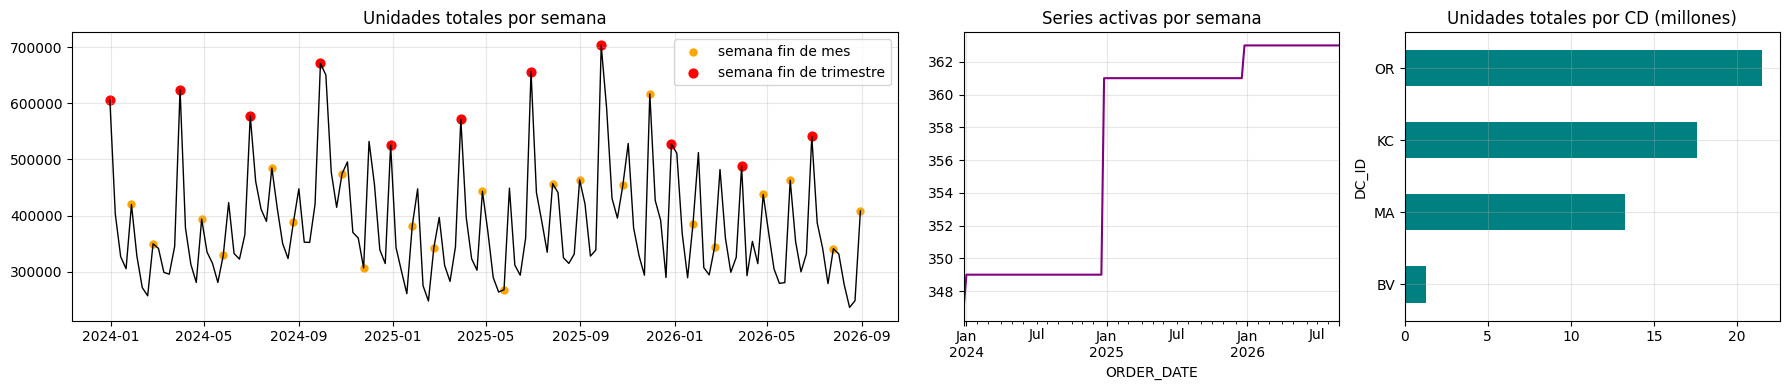

In [4]:
def marcas_calendario(f):
    """Semana (dom-sáb) que contiene el último día del mes / del trimestre. Reutilizable para fechas futuras."""
    f = pd.DatetimeIndex(f)
    fin_mes = (f + pd.offsets.MonthEnd(0) - f).days <= 6
    return pd.DataFrame({"fin_mes": fin_mes, "fin_trim": fin_mes & f.month.isin([3, 6, 9, 12])}, index=f)

cal = marcas_calendario(panel.ORDER_DATE)
panel["fin_mes"], panel["fin_trim"] = cal.fin_mes.values, cal.fin_trim.values
panel["trimestre"] = panel.ORDER_DATE.dt.to_period("Q").astype(str)

tot = panel.groupby("ORDER_DATE").y.sum(); m = marcas_calendario(tot.index)
fig, ax = plt.subplots(1, 3, figsize=(18, 4), gridspec_kw={"width_ratios": [2.2, 1, 1]})
ax[0].plot(tot, color="black", lw=1)
ax[0].scatter(tot.index[m.fin_mes & ~m.fin_trim], tot[m.fin_mes & ~m.fin_trim], c="orange", s=25, label="semana fin de mes")
ax[0].scatter(tot.index[m.fin_trim], tot[m.fin_trim], c="red", s=40, label="semana fin de trimestre")
ax[0].set_title("Unidades totales por semana"); ax[0].legend()
panel.groupby("ORDER_DATE").size().plot(ax=ax[1], color="purple", title="Series activas por semana")
(panel.groupby("DC_ID").y.sum() / 1e6).sort_values().plot.barh(ax=ax[2], color="teal", title="Unidades totales por CD (millones)")
plt.tight_layout(); plt.show()

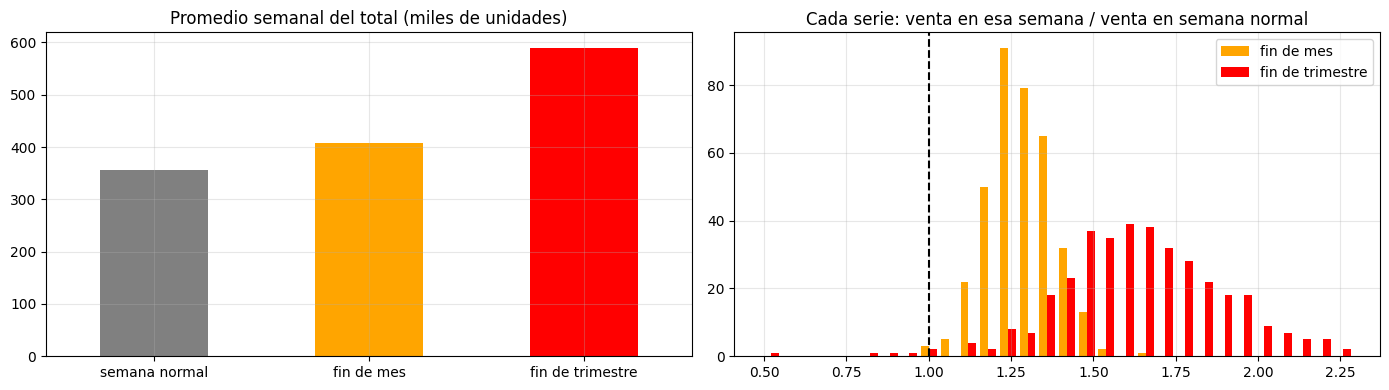

mediana de series: fin de mes = 1.28x | fin de trimestre = 1.63x


In [5]:
cat = np.select([tot.index.isin(tot.index[m.fin_trim]), m.fin_mes.values], ["fin de trimestre", "fin de mes"], "semana normal")
med = tot.groupby(cat).mean() / 1e3
r = panel.groupby(["DC_ID", "SKU_NBR", "fin_mes"]).y.mean().unstack(); r_mes = r[True] / r[False]
r = panel.groupby(["DC_ID", "SKU_NBR", "fin_trim"]).y.mean().unstack(); r_trim = r[True] / r[False]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
med.reindex(["semana normal", "fin de mes", "fin de trimestre"]).plot.bar(ax=ax[0], color=["gray", "orange", "red"], rot=0, title="Promedio semanal del total (miles de unidades)")
ax[1].hist([r_mes.dropna(), r_trim.dropna()], bins=30, label=["fin de mes", "fin de trimestre"], color=["orange", "red"])
ax[1].axvline(1, color="k", ls="--"); ax[1].legend(); ax[1].set_title("Cada serie: venta en esa semana / venta en semana normal")
plt.tight_layout(); plt.show()
print(f"mediana de series: fin de mes = {r_mes.median():.2f}x | fin de trimestre = {r_trim.median():.2f}x")

RESULTADO: LAS SEMANAS DE FIN DE MES TIENEN UNA DEMANDA MEDIANA 1,28 VECES MAYOR QUE LAS SEMANAS NORMALES, EN FIN DE TRIMESTRE LA MEDIANA ES 1,63 VECES MAYOR, EL PATRON APARECE EN LA MAYORIA DE LAS SERIES.

### DECISION 3, PICOS DE CIERRE
LOS PICOS DE FIN DE MES Y FIN DE TRIMESTRE SE CONSERVAN, SON PREDECIBLES Y ELIMINARLOS PODRIA SUBESTIMAR LA DEMANDA, SE IDENTIFICAN CON LAS VARIABLES fin_mes Y fin_trim.

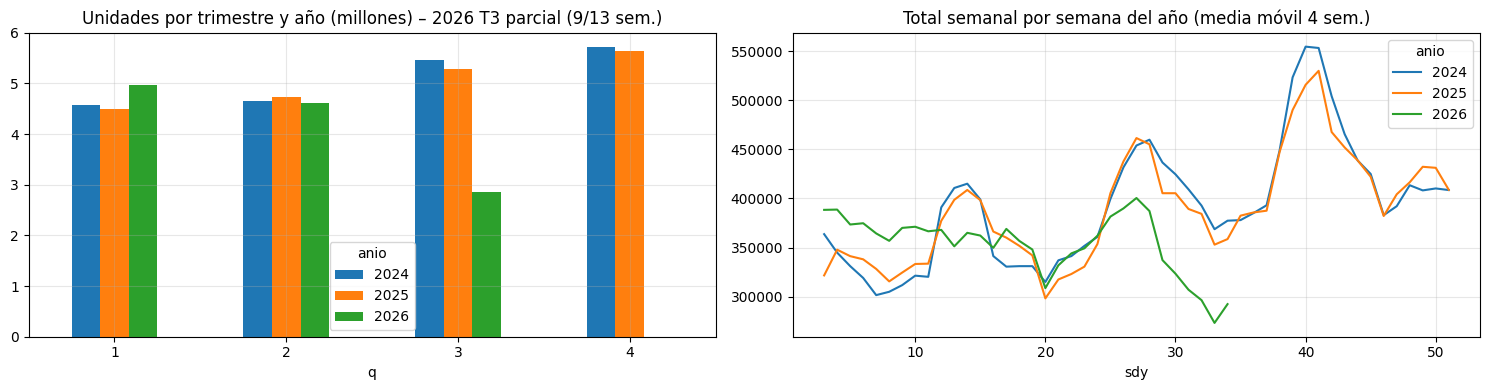

variación interanual por trimestre completo (%): {'2025Q1': -1.3, '2025Q2': 1.8, '2025Q3': -3.3, '2025Q4': -1.1, '2026Q1': 10.2, '2026Q2': -2.2}
primeras 9 semanas del T3 -> 2024: 3.67 M | 2025: 3.50 M | 2026: 2.85 M  (-18.5% vs 2025)


In [6]:
q = panel.assign(anio=panel.ORDER_DATE.dt.year, q=panel.ORDER_DATE.dt.quarter).groupby(["anio", "q"]).y.sum().unstack(0).drop(columns=2023) / 1e6
sem = panel.assign(anio=panel.ORDER_DATE.dt.year, sdy=panel.ORDER_DATE.dt.isocalendar().week.astype(int)).groupby(["sdy", "anio"]).y.sum().unstack().drop(columns=2023)
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
q.plot.bar(ax=ax[0], rot=0, title="Unidades por trimestre y año (millones) – 2026 T3 parcial (9/13 sem.)")
sem.rolling(4, center=True).mean().plot(ax=ax[1], title="Total semanal por semana del año (media móvil 4 sem.)")
plt.tight_layout(); plt.show()
qt = panel.groupby("trimestre").agg(u=("y", "sum"), n_sem=("ORDER_DATE", "nunique"))
yoy = (qt[qt.n_sem == 13].u.pct_change(4) * 100).round(1)                     # solo trimestres completos
print("variación interanual por trimestre completo (%):", yoy.dropna().to_dict())
t9 = lambda a: tot[(tot.index >= f"{a}-07-01") & (tot.index <= f"{a}-09-30")].iloc[:9].sum()   # primeras 9 semanas del T3
print(f"primeras 9 semanas del T3 -> 2024: {t9(2024)/1e6:.2f} M | 2025: {t9(2025)/1e6:.2f} M | 2026: {t9(2026)/1e6:.2f} M  ({t9(2026)/t9(2025)-1:+.1%} vs 2025)")

RESULTADO: EN 2024 Y 2025, Q1 Y Q2 TIENEN MENOR DEMANDA QUE Q3 Y Q4, Q4 RONDA 5,7 MILLONES DE UNIDADES Y EL MAXIMO OCURRE ENTRE SEPTIEMBRE Y OCTUBRE, LOS TRIMESTRES COMPLETOS HASTA Q2 DE 2026 VARIAN ENTRE MENOS 3 Y MAS 10 POR CIENTO INTERANUAL.

LAS 9 SEMANAS OBSERVADAS DE Q3 DE 2026 SUMAN 2,85 MILLONES DE UNIDADES, 18,5 POR CIENTO MENOS QUE EL MISMO PERIODO DE 2025, ESTA DIFERENCIA DEBE CONSIDERARSE AL PRONOSTICAR EL CIERRE DE Q3 Y Q4.

### DECISION 4, ESTACIONALIDAD
EL HISTORIAL CONTIENE CERCA DE 2,7 CICLOS ANUALES, POR ESO SE EVITA UN MODELO CON ESTACIONALIDAD ANUAL COMPLEJA, EL SARIMA DE COMPARACION DEBE MANTENER UNA ESPECIFICACION SIMPLE Y RESPETAR LA VALIDACION TEMPORAL.

extremos (z>8): 286 filas = 0.57% | 1.10% de las unidades
  caen en semana de fin de mes: 70% (esas semanas son el 24% del calendario)
  atípicos reales (no fin de mes): 85 filas = 0.34% de las unidades


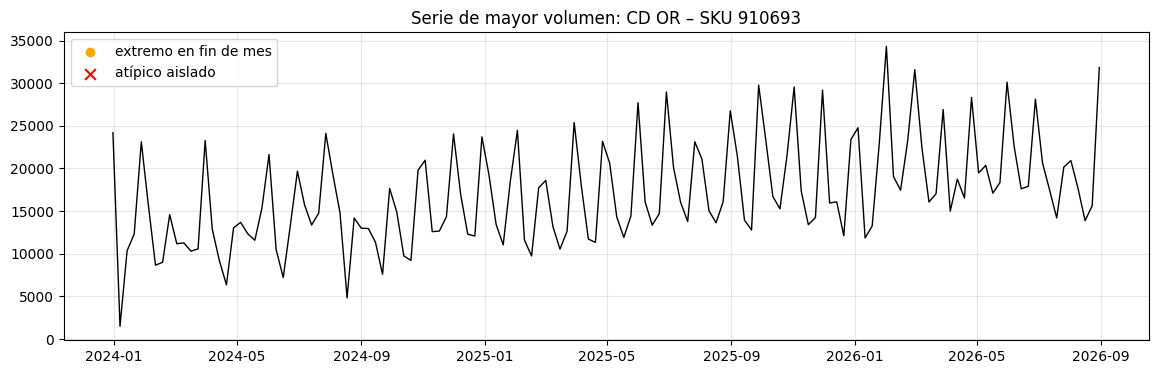

In [7]:
def z_robusto(x):                       # distancia a la mediana móvil de 13 sem. en unidades de MAD
    med = x.rolling(13, center=True, min_periods=5).median()
    mad = (x - med).abs().rolling(13, center=True, min_periods=5).median()
    return (x - med) / (1.4826 * mad.replace(0, np.nan))

panel["z"] = panel.groupby(["DC_ID", "SKU_NBR"]).y.transform(z_robusto)
ext = panel[panel.z > 8]
panel["atipico"] = (panel.z > 8) & ~panel.fin_mes          # extremo Y fuera de semana de cierre
print(f"extremos (z>8): {len(ext)} filas = {len(ext)/len(panel):.2%} | {ext.y.sum()/panel.y.sum():.2%} de las unidades")
print(f"  caen en semana de fin de mes: {ext.fin_mes.mean():.0%} (esas semanas son el {panel.fin_mes.mean():.0%} del calendario)")
print(f"  atípicos reales (no fin de mes): {panel.atipico.sum()} filas = {panel[panel.atipico].y.sum()/panel.y.sum():.2%} de las unidades")

top = panel.groupby(["DC_ID", "SKU_NBR"]).y.sum().idxmax(); s = panel[(panel.DC_ID == top[0]) & (panel.SKU_NBR == top[1])]
plt.figure(figsize=(14, 4)); plt.plot(s.ORDER_DATE, s.y, color="black", lw=1)
plt.scatter(s.ORDER_DATE[s.z > 8], s.y[s.z > 8], c="orange", label="extremo en fin de mes"); plt.scatter(s.ORDER_DATE[s.atipico], s.y[s.atipico], c="red", marker="x", s=60, label="atípico aislado")
plt.title(f"Serie de mayor volumen: CD {top[0]} – SKU {top[1]}"); plt.legend(); plt.show()

RESULTADO: EL 70 POR CIENTO DE LOS VALORES EXTREMOS OCURRE EN SEMANAS DE FIN DE MES, LOS ATIPICOS AISLADOS REPRESENTAN 85 FILAS Y 0,34 POR CIENTO DE LAS UNIDADES.

### DECISION 5, VALORES ATIPICOS
LA DEMANDA ORIGINAL SE CONSERVA Y LOS EXTREMOS SE MARCAN PARA SU REVISION, LA DETECCION ACTUAL ES EXPLORATORIA PORQUE USA VENTANAS CENTRADAS, CUALQUIER REGLA USADA PARA ENTRENAR DEBE RECALCULARSE SOLO CON DATOS ANTERIORES A CADA PRUEBA.

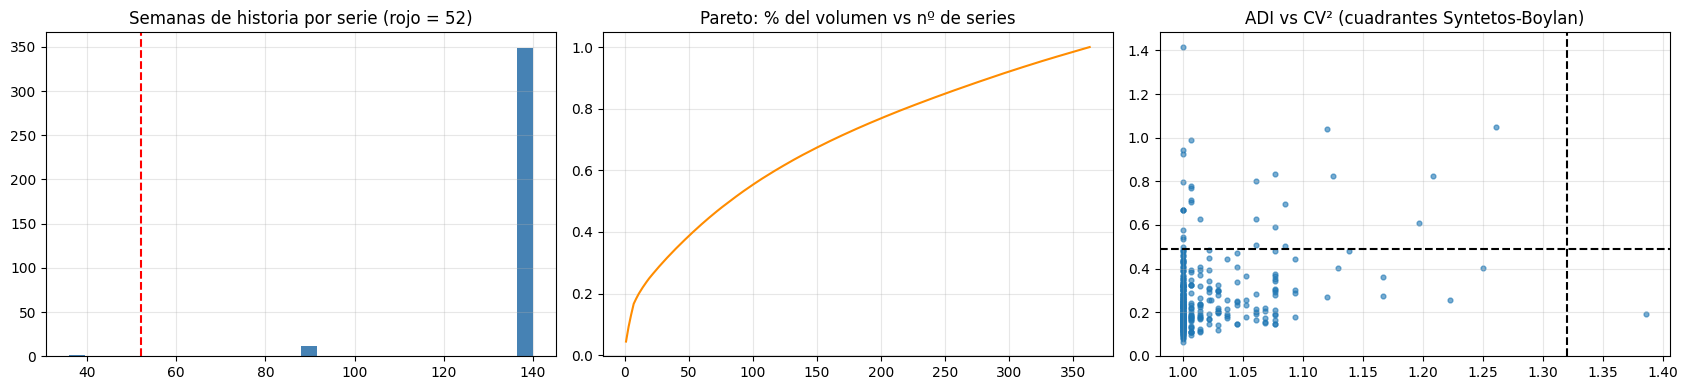

{'smooth': 333, 'erratic': 29, 'intermittent': 1} | ABC: {'A': 219, 'B': 104, 'C': 40} | series cortas: 2
volumen por clase ABC: {'A': 0.8, 'B': 0.15, 'C': 0.049}


In [8]:
k = ["DC_ID", "SKU_NBR"]
info = pd.DataFrame({"n_sem": panel.groupby(k).size(), "total": panel.groupby(k).y.sum(), "pct_ceros": panel.assign(c=panel.y == 0).groupby(k).c.mean()})
nz = panel[panel.y > 0].groupby(k).y
info["adi"] = info.n_sem / nz.size()                          # semanas por cada semana con pedido
info["cv2"] = (nz.std(ddof=0) / nz.mean()) ** 2               # variabilidad del tamaño del pedido
info["clase"] = np.select([(info.adi < 1.32) & (info.cv2 < .49), (info.adi >= 1.32) & (info.cv2 < .49), (info.adi < 1.32) & (info.cv2 >= .49)],
                          ["smooth", "intermittent", "erratic"], "lumpy")
cs = info.total.sort_values(ascending=False).cumsum() / info.total.sum()
info["abc"] = pd.cut(cs.shift(fill_value=0).reindex(info.index), [-1, .8, .95, 1.0001], labels=list("ABC"))
info["corta"] = info.n_sem < 52

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].hist(info.n_sem, bins=30, color="steelblue"); ax[0].axvline(52, color="r", ls="--"); ax[0].set_title("Semanas de historia por serie (rojo = 52)")
ax[1].plot(range(1, len(cs) + 1), cs.values, color="darkorange"); ax[1].set_title("Pareto: % del volumen vs nº de series")
ax[2].scatter(info.adi, info.cv2, s=12, alpha=.6); ax[2].axvline(1.32, color="k", ls="--"); ax[2].axhline(.49, color="k", ls="--"); ax[2].set_title("ADI vs CV² (cuadrantes Syntetos-Boylan)")
plt.tight_layout(); plt.show()
print(info.clase.value_counts().to_dict(), "| ABC:", info.abc.value_counts().to_dict(), "| series cortas:", info.corta.sum())
print("volumen por clase ABC:", (info.groupby("abc", observed=True).total.sum() / info.total.sum()).round(3).to_dict())

RESULTADO: EL ADI ES APROXIMADAMENTE 1,02, HAY 333 SERIES SMOOTH, 29 ERRATIC Y 1 INTERMITTENT, LA MAYORIA DE LAS SERIES TIENE DEMANDA FRECUENTE.
LAS 219 SERIES DE CLASE A REPRESENTAN EL 80 POR CIENTO DEL VOLUMEN, LAS 104 DE CLASE B REPRESENTAN EL 15 POR CIENTO Y LAS 40 DE CLASE C EL 5 POR CIENTO.
349 SERIES TIENEN AL MENOS 104 SEMANAS DE HISTORIA, 14 TIENEN MENOS Y 2 SERIES DEL CENTRO OR TIENEN 36 SEMANAS.

### DECISION 6, SEGMENTACION DE SERIES
NO SE PRIORIZA UN MODELO PARA DEMANDA INTERMITENTE PORQUE SOLO UNA SERIE TIENE ESA CLASIFICACION, LAS SERIES ERRATICAS SE EVALUAN POR SEPARADO.
SE CONSIDERAN CORTAS LAS SERIES CON MENOS DE 52 SEMANAS, LA CLASIFICACION ABC SE USA PARA DESCRIBIR RESULTADOS POR VOLUMEN Y NO PARA ENTRENAR MODELOS.

In [9]:
panel = panel.join(info[["abc", "clase", "corta"]], on=["DC_ID", "SKU_NBR"]).drop(columns="z")

horizonte = pd.date_range(panel.ORDER_DATE.max() + pd.Timedelta(days=7), "2026-12-27", freq="7D")
print(panel.shape, "| series:", panel.groupby(["DC_ID", "SKU_NBR"]).ngroups, "| última semana:", panel.ORDER_DATE.max().date())
print(f"horizonte: {len(horizonte)} semanas ({horizonte[0].date()} -> {horizonte[-1].date()}) | de ellas en Q3-2026: {(horizonte.to_period('Q') == pd.Period('2026Q3')).sum()}")
panel.head()

(49986, 11) | series: 363 | última semana: 2026-08-30
horizonte: 17 semanas (2026-09-06 -> 2026-12-27) | de ellas en Q3-2026: 4


,DC_ID,SKU_NBR,ORDER_DATE,y,fin_mes,fin_trim,trimestre,atipico,abc,clase,corta
0,BV,108646,2024-12-29,691,True,True,2024Q4,False,C,smooth,False
1,BV,108646,2025-01-05,688,False,False,2025Q1,False,C,smooth,False
2,BV,108646,2025-01-12,486,False,False,2025Q1,False,C,smooth,False
3,BV,108646,2025-01-19,402,False,False,2025Q1,False,C,smooth,False
4,BV,108646,2025-01-26,281,True,False,2025Q1,False,C,smooth,False


## PUNTO 2

## METODOLOGIA DE EVALUACION

SE COMPARAN CUATRO MODELOS BASE, DOS REFERENCIAS SIMPLES (NAIVE DE LA ULTIMA SEMANA Y NAIVE ESTACIONAL DE 52 SEMANAS), LA MEDIA MOVIL DE 13 SEMANAS QUE CORRESPONDE AL METODO ACTUAL Y UN SARIMA SIMPLE CON ORDEN FIJO, LAS PREDICCIONES SE MIDEN EN LOS MISMOS FOLDS, CON EL MISMO HORIZONTE Y SOBRE LAS MISMAS SERIES.

LA VALIDACION USA ORIGEN MOVIL, CADA MODELO SE AJUSTA SOLO CON LAS SEMANAS ANTERIORES AL TRIMESTRE DE PRUEBA, LOS SEIS PRIMEROS FOLDS SON TRIMESTRES COMPLETOS Y EL ULTIMO FOLD PARCIAL SE REPORTA POR SEPARADO.

WAPE ES EL ERROR ABSOLUTO TOTAL DIVIDIDO POR LA DEMANDA REAL TOTAL, UN VALOR MENOR INDICA MENOR ERROR, EL SESGO ES LA DIFERENCIA ENTRE PRONOSTICO Y REAL DIVIDIDA POR LA DEMANDA REAL, UN SESGO POSITIVO INDICA SOBREPRONOSTICO Y UNO NEGATIVO INDICA SUBPRONOSTICO.

EL SARIMA SE DEFINE COMO SARIMA 1 0 0 POR 1 0 0 DE PERIODO 13, LA PARTE ESTACIONAL DE PERIODO 13 REPRESENTA EL PICO DE FIN DE TRIMESTRE, QUE SE REPITE CADA 13 SEMANAS (DECISION 3), SE USA UN MINIMO DE 26 OBSERVACIONES DE ENTRENAMIENTO PARA TENER DOS CICLOS COMPLETOS, LAS SERIES CON MENOS HISTORIA SE EXCLUYEN DE AMBOS MODELOS EN ESE FOLD Y SU COBERTURA SE REPORTA.

EL NAIVE REPITE LA ULTIMA SEMANA OBSERVADA, COMO EL ORIGEN DE CADA FOLD ES SIEMPRE LA SEMANA DE CIERRE DE TRIMESTRE (PICO DE 1,63 VECES, DECISION 3), SE ESPERA QUE SOBREPRONOSTIQUE Y SIRVE COMO PISO DE REFERENCIA. EL NAIVE ESTACIONAL REPITE LAS MISMAS SEMANAS DE HACE 52 SEMANAS, CONSERVA EL PICO DE CIERRE Y EL NIVEL ANUAL SIN ESTIMAR NINGUN PARAMETRO, SI LA SERIE NO EXISTIA HACE UN ANIO USA SU MEDIA MOVIL DE 13 SEMANAS.

POR QUE NO SE USA SARIMA CON PERIODO 52: LA DECISION 4 INDICA QUE EL HISTORIAL TIENE 2,7 CICLOS ANUALES Y UN SARIMA DE PERIODO 52 NECESITA AL MENOS DOS CICLOS COMPLETOS (104 SEMANAS) PARA ESTIMAR LA PARTE ESTACIONAL, ESO SOLO SE CUMPLE EN LOS FOLDS 5, 6 Y 7 (105, 118 Y 131 SEMANAS) Y NO PERMITIRIA COMPARAR LOS FOLDS 1 A 4, ADEMAS EL AJUSTE POR SERIE SERIA MAS LENTO E INESTABLE CON TAN POCOS CICLOS. LA ESTACIONALIDAD ANUAL YA QUEDA CUBIERTA POR EL NAIVE ESTACIONAL DE 52 SEMANAS Y LA DE CIERRE DE TRIMESTRE POR EL SARIMA DE PERIODO 13.

 fold     origen test_inicio   test_fin trimestre  n_train  n_test  trimestre_completo  series_activas  series_nuevas  porcentaje_unidades_nuevas
    1 2024-12-29  2025-01-05 2025-03-30    2025Q1       53      13                True             361              2                    0.000000
    2 2025-03-30  2025-04-06 2025-06-29    2025Q2       66      13                True             361              2                    0.000000
    3 2025-06-29  2025-07-06 2025-09-28    2025Q3       79      13                True             361              2                    0.000000
    4 2025-09-28  2025-10-05 2025-12-28    2025Q4       92      13                True             361              2                    0.000438
    5 2025-12-28  2026-01-04 2026-03-29    2026Q1      105      13                True             363              0                    0.000000
    6 2026-03-29  2026-04-05 2026-06-28    2026Q2      118      13                True             363              0       

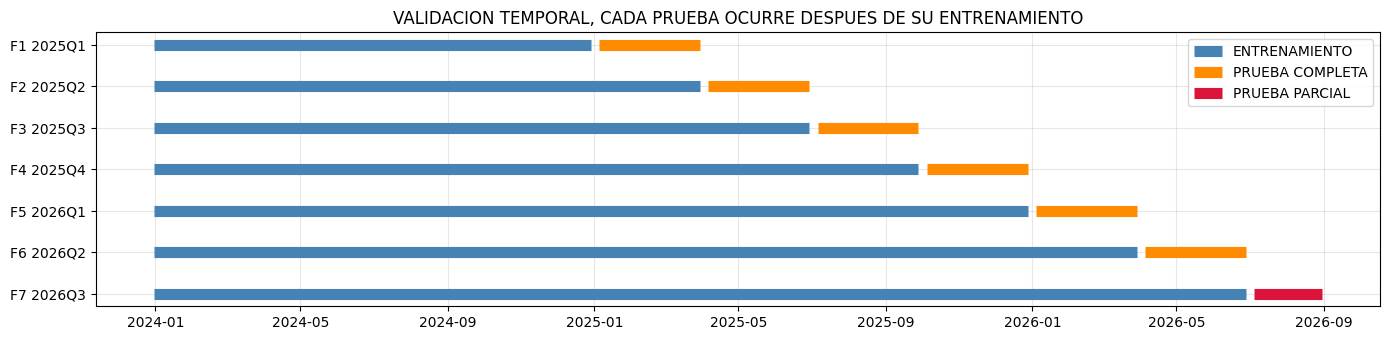

In [10]:
MIN_TRAIN, H_MAX = 52, 13
semanas = pd.date_range(panel.ORDER_DATE.min(), panel.ORDER_DATE.max(), freq="7D")
cal_s = marcas_calendario(semanas)
origenes = [o for o in semanas[cal_s.fin_trim.to_numpy()] if semanas.get_loc(o) + 1 >= MIN_TRAIN]

Y = panel.pivot(index=["DC_ID", "SKU_NBR"], columns="ORDER_DATE", values="y").reindex(columns=semanas)
M = Y.to_numpy(dtype=float)
dcs = Y.index.get_level_values("DC_ID").to_numpy()
skus = Y.index.get_level_values("SKU_NBR").to_numpy()

filas = []
for fold, origen in enumerate(origenes, start=1):
    i = semanas.get_loc(origen)
    horizonte = min(H_MAX, len(semanas) - i - 1)
    activas = ~np.isnan(M[:, i])
    futuras = M[:, i + 1:i + horizonte + 1]
    excluidas = np.nansum(futuras[~activas])
    total = np.nansum(futuras)
    filas.append({
        "fold": fold,
        "origen": origen,
        "test_inicio": semanas[i + 1],
        "test_fin": semanas[i + horizonte],
        "trimestre": str(semanas[i + 1].to_period("Q")),
        "n_train": i + 1,
        "n_test": horizonte,
        "trimestre_completo": horizonte == H_MAX,
        "series_activas": int(activas.sum()),
        "series_nuevas": int((~activas).sum()),
        "porcentaje_unidades_nuevas": excluidas / total if total else np.nan,
        "i_origen": i,
    })
folds = pd.DataFrame(filas)
print(folds.drop(columns="i_origen").to_string(index=False))

fig, ax = plt.subplots(figsize=(14, 3.5))
for f in folds.itertuples():
    ax.hlines(f.fold, semanas[0], f.origen, color="steelblue", linewidth=8,
              label="ENTRENAMIENTO" if f.fold == 1 else None)
    ax.hlines(f.fold, f.test_inicio, f.test_fin,
              color="darkorange" if f.trimestre_completo else "crimson", linewidth=8,
              label="PRUEBA COMPLETA" if f.fold == 1 else ("PRUEBA PARCIAL" if not f.trimestre_completo else None))
ax.set_yticks(folds.fold)
ax.set_yticklabels([f"F{f.fold} {f.trimestre}" for f in folds.itertuples()])
ax.invert_yaxis()
ax.set_title("VALIDACION TEMPORAL, CADA PRUEBA OCURRE DESPUES DE SU ENTRENAMIENTO")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## LECTURA DE LA SEPARACION TEMPORAL

CADA FOLD USA UNA VENTANA EXPANSIVA, ESTO SIGNIFICA QUE EL ENTRENAMIENTO CRECE CON EL TIEMPO Y SOLO INCLUYE DATOS DISPONIBLES ANTES DEL ORIGEN, LOS PRONOSTICOS CUBREN EL TRIMESTRE SIGUIENTE SIN ACTUALIZAR EL MODELO DENTRO DE LA PRUEBA.

LOS TRIMESTRES COMPLETOS SE USAN PARA COMPARAR MODELOS, EL FOLD PARCIAL ES UN CONTROL RECIENTE Y NO SE MEZCLA CON EL PROMEDIO DE TRIMESTRES COMPLETOS, LAS SERIES NUEVAS O CON MENOS DE 26 SEMANAS SE EXCLUYEN DE TODOS LOS MODELOS PARA MANTENER UNA COMPARACION EQUITATIVA.

In [11]:
from statsforecast import StatsForecast
from statsforecast.models import ARIMA

MIN_SARIMA_TRAIN = 26
pronosticos, cobertura = [], []

def sarima_seguro(df_train, H):
    """Ajusta todas las series juntas; si alguna falla, las ajusta una por una y descarta solo las que fallan."""
    nuevo = lambda: StatsForecast(models=[ARIMA(order=(1, 0, 0), season_length=13, seasonal_order=(1, 0, 0), alias="SARIMA")], freq="W-SUN", n_jobs=1)
    try:
        return nuevo().forecast(df=df_train, h=H)
    except Exception:
        salidas = []
        for _, serie in df_train.groupby("unique_id"):
            try: salidas.append(nuevo().forecast(df=serie, h=H))
            except Exception: pass          # el ajuste no converge: la serie queda fuera de ambos modelos
        return pd.concat(salidas)

for f in folds.itertuples():
    i, H = f.i_origen, f.n_test
    filas_train, filas_test, medias = [], [], {}
    naive, snaive = {}, {}
    activas = 0
    series_cortas = 0
    total_unidades = np.nansum(M[:, i + 1:i + H + 1])

    for j in range(M.shape[0]):
        historia_completa = M[j, :i + 1]
        historia = historia_completa[~np.isnan(historia_completa)]
        if np.isnan(M[j, i]):
            continue
        activas += 1
        if len(historia) < MIN_SARIMA_TRAIN:
            series_cortas += 1
            continue

        fechas_historia = semanas[i - len(historia) + 1:i + 1]
        for fecha, valor in zip(fechas_historia, historia):
            filas_train.append({"unique_id": j, "ds": fecha, "y": valor})

        real = M[j, i + 1:i + H + 1]
        if len(real) != H or np.isnan(real).any():
            continue
        medias[j] = float(np.mean(historia[-13:]))
        naive[j] = float(historia[-1])                                   # ultima semana observada
        previo = M[j, i + 1 - 52:i + H + 1 - 52]                         # las mismas semanas, 52 semanas antes
        snaive[j] = np.where(np.isnan(previo), medias[j], previo)        # si la serie no existia, se usa su MA13
        for fecha, valor in zip(semanas[i + 1:i + H + 1], real):
            filas_test.append({"unique_id": j, "DC_ID": dcs[j], "SKU_NBR": skus[j], "ds": fecha, "y": valor})

    pred = sarima_seguro(pd.DataFrame(filas_train), H)
    pred = pred.rename(columns={"ds": "ORDER_DATE", "SARIMA": "sarima"})
    pred = pred.merge(
        pd.DataFrame(filas_test).rename(columns={"ds": "ORDER_DATE"}),
        on=["unique_id", "ORDER_DATE"],
        how="inner",
        validate="one_to_one",
    )
    pred["sarima"] = pred["sarima"].clip(lower=0)
    pred["ma13"] = pred["unique_id"].map(medias)
    pred["naive"] = pred["unique_id"].map(naive)
    semana_h = ((pred["ORDER_DATE"] - f.test_inicio).dt.days // 7).to_numpy()
    pred["snaive"] = [snaive[u][k] for u, k in zip(pred["unique_id"], semana_h)]
    pred = pred[np.isfinite(pred["sarima"]) & pred["ma13"].notna()]

    for fila in pred.itertuples(index=False):
        pronosticos.append({
            "fold": f.fold,
            "DC_ID": fila.DC_ID,
            "SKU_NBR": fila.SKU_NBR,
            "ORDER_DATE": fila.ORDER_DATE,
            "h": (fila.ORDER_DATE - f.test_inicio).days // 7 + 1,
            "y": fila.y,
            "naive": fila.naive,
            "snaive": fila.snaive,
            "ma13": fila.ma13,
            "sarima": fila.sarima,
        })

    unidades_evaluadas = pred["y"].sum()
    cobertura.append({
        "fold": f.fold,
        "series_activas": activas,
        "series_con_menos_de_26_semanas": series_cortas,
        "series_comparadas": int(pred["unique_id"].nunique()),
        "series_sin_ajuste_sarima": activas - series_cortas - int(pred["unique_id"].nunique()),
        "porcentaje_unidades_evaluadas": unidades_evaluadas / total_unidades if total_unidades else np.nan,
    })

fc = pd.DataFrame(pronosticos)
if fc.empty:
    raise RuntimeError("NO SE GENERARON PRONOSTICOS, REVISE LOS DATOS Y LA CONFIGURACION SARIMA")

print("COBERTURA DE LA COMPARACION")
print(pd.DataFrame(cobertura).to_string(index=False, formatters={"porcentaje_unidades_evaluadas": "{:.1%}".format}))

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


COBERTURA DE LA COMPARACION
 fold  series_activas  series_con_menos_de_26_semanas  series_comparadas  series_sin_ajuste_sarima porcentaje_unidades_evaluadas
    1             361                              12                344                         5                         95.3%
    2             361                              12                342                         7                         94.4%
    3             361                               0                358                         3                         98.9%
    4             361                               0                356                         5                         98.3%
    5             363                               2                360                         1                         99.0%
    6             363                               2                358                         3                         96.4%
    7             363                               0                

## METRICAS Y COMPARACION

LAS PREDICCIONES DE TODOS LOS MODELOS SE CALCULAN PARA LAS MISMAS SERIES Y SEMANAS, SI UN AJUSTE SARIMA FALLA ESA SERIE SE EXCLUYE TAMBIEN DEL RESULTADO DE LOS DEMAS MODELOS, LA COBERTURA MUESTRA QUE PARTE DEL VOLUMEN QUEDO INCLUIDA.

EL WAPE SE PRESENTA POR SEMANA Y POR TRIMESTRE, EN SKU POR CENTRO, SKU Y TOTAL DEL SEGMENTO, LOS FOLDS COMPLETOS SE RESUMEN CON EL PROMEDIO DE SUS WAPE TRIMESTRALES Y EL PERIODO PARCIAL SE MUESTRA APARTE.

PROMEDIO DE LOS TRIMESTRES COMPLETOS


modelo,ma13,naive,sarima,snaive
nivel,,,,
SEMANAL SKU POR CD,0.377,0.652,0.345,0.488
SEMANAL TOTAL,0.233,0.532,0.164,0.103
TRIMESTRAL SKU,0.219,0.561,0.218,0.348
TRIMESTRAL SKU POR CD,0.246,0.584,0.254,0.399
TRIMESTRAL TOTAL,0.125,0.516,0.093,0.060


SESGO PROMEDIO DE LOS TRIMESTRES COMPLETOS, POSITIVO ES SOBREPRONOSTICO, ES IGUAL EN TODOS LOS NIVELES


modelo,ma13,naive,sarima,snaive
sesgo,0.057,0.516,0.091,0.031


RESULTADOS POR FOLD, EL PERIODO PARCIAL SE REPORTA POR SEPARADO


modelo                       ma13  naive  sarima  snaive
fold nivel                                              
1    SEMANAL SKU POR CD     0.576  0.726   0.481   0.480
     SEMANAL TOTAL          0.370  0.549   0.271   0.125
     TRIMESTRAL SKU         0.424  0.619   0.334   0.344
     TRIMESTRAL SKU POR CD  0.471  0.645   0.383   0.382
     TRIMESTRAL TOTAL       0.322  0.533   0.228   0.061
2    SEMANAL SKU POR CD     0.343  0.714   0.364   0.520
     SEMANAL TOTAL          0.203  0.611   0.185   0.079
     TRIMESTRAL SKU         0.193  0.620   0.240   0.374
     TRIMESTRAL SKU POR CD  0.215  0.647   0.282   0.440
     TRIMESTRAL TOTAL       0.037  0.575   0.088   0.034
3    SEMANAL SKU POR CD     0.308  0.715   0.287   0.554
     SEMANAL TOTAL          0.184  0.630   0.107   0.102
     TRIMESTRAL SKU         0.155  0.642   0.167   0.393
     TRIMESTRAL SKU POR CD  0.165  0.650   0.199   0.455
     TRIMESTRAL TOTAL       0.106  0.611   0.010   0.072
4    SEMANAL SKU POR CD     0.296  0.704   0.247   0.521
     SEMANAL TOTAL          0.193  0.621   0.112   0.093
     TRIMESTRAL SKU         0.134  0.659   0.121   0.355
     TRIMESTRAL SKU POR CD  0.152  0.677   0.146   0.430
     TRIMESTRAL TOTAL       0.062  0.621   0.005   0.053
5    SEMANAL SKU POR CD     0.425  0.546   0.373   0.448
     SEMANAL TOTAL          0.244  0.381   0.128   0.131
     TRIMESTRAL SKU         0.254  0.412   0.265   0.333
     TRIMESTRAL SKU POR CD  0.303  0.430   0.304   0.361
     TRIMESTRAL TOTAL       0.145  0.381   0.099   0.085
6    SEMANAL SKU POR CD     0.314  0.510   0.318   0.403
     SEMANAL TOTAL          0.206  0.401   0.182   0.088
     TRIMESTRAL SKU         0.152  0.412   0.179   0.286
     TRIMESTRAL SKU POR CD  0.173  0.456   0.212   0.324
     TRIMESTRAL TOTAL       0.080  0.376   0.128   0.052
7    SEMANAL SKU POR CD     0.305  0.768   0.323   0.455
     SEMANAL TOTAL          0.182  0.708   0.231   0.241
     TRIMESTRAL SKU         0.161  0.749   0.262   0.349
     TRIMESTRAL SKU POR CD  0.193  0.751   0.281   0.388
     TRIMESTRAL TOTAL       0.123  0.708   0.231   0.241

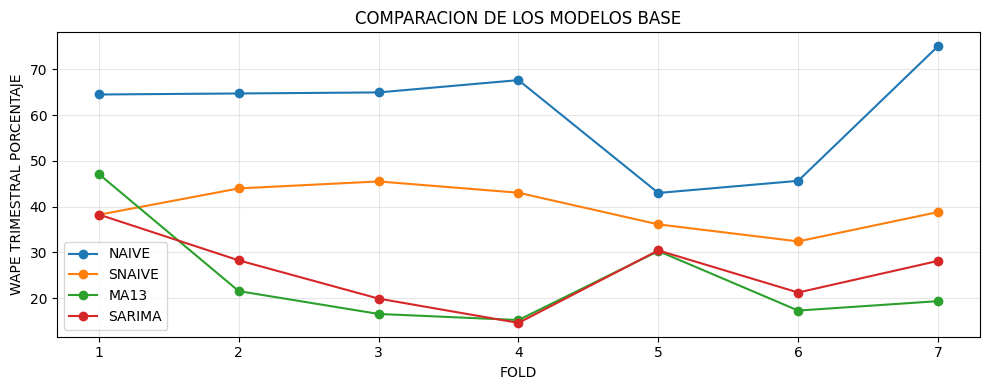

In [12]:
MODELOS_BASE = ["naive", "snaive", "ma13", "sarima"]
NIVELES = {
    "SEMANAL SKU POR CD": ["DC_ID", "SKU_NBR", "ORDER_DATE"],
    "SEMANAL TOTAL": ["ORDER_DATE"],
    "TRIMESTRAL SKU POR CD": ["DC_ID", "SKU_NBR"],
    "TRIMESTRAL SKU": ["SKU_NBR"],
    "TRIMESTRAL TOTAL": [],
}

filas_metricas = []
for fold, datos_fold in fc.groupby("fold"):
    for nivel, llaves in NIVELES.items():
        columnas = ["y"] + MODELOS_BASE
        agregado = datos_fold.groupby(llaves, observed=True)[columnas].sum() if llaves else datos_fold[columnas].sum().to_frame().T
        denominador = agregado["y"].sum()
        for modelo in MODELOS_BASE:
            error = agregado[modelo] - agregado["y"]
            filas_metricas.append({
                "fold": fold,
                "nivel": nivel,
                "modelo": modelo,
                "wape": error.abs().sum() / denominador if denominador else np.nan,
                "sesgo": error.sum() / denominador if denominador else np.nan,
            })

metricas_p2 = pd.DataFrame(filas_metricas)
folds_completos = folds.loc[folds.trimestre_completo, "fold"].tolist()
resumen_completos = (
    metricas_p2[metricas_p2.fold.isin(folds_completos)]
    .groupby(["nivel", "modelo"], as_index=False)[["wape", "sesgo"]]
    .mean()
)
print("PROMEDIO DE LOS TRIMESTRES COMPLETOS")
display(resumen_completos.pivot(index="nivel", columns="modelo", values="wape").round(3))
print("SESGO PROMEDIO DE LOS TRIMESTRES COMPLETOS, POSITIVO ES SOBREPRONOSTICO, ES IGUAL EN TODOS LOS NIVELES")
display(resumen_completos.groupby("modelo")[["sesgo"]].mean().round(3).T)
print("RESULTADOS POR FOLD, EL PERIODO PARCIAL SE REPORTA POR SEPARADO")
display(metricas_p2.pivot_table(index=["fold", "nivel"], columns="modelo", values="wape").round(3))

trimestral = metricas_p2[metricas_p2.nivel == "TRIMESTRAL SKU POR CD"]
fig, ax = plt.subplots(figsize=(10, 4))
for modelo in MODELOS_BASE:
    datos = trimestral[trimestral.modelo == modelo]
    ax.plot(datos.fold, datos.wape * 100, marker="o", label=modelo.upper())
ax.set_xticks(folds.fold)
ax.set_xlabel("FOLD")
ax.set_ylabel("WAPE TRIMESTRAL PORCENTAJE")
ax.set_title("COMPARACION DE LOS MODELOS BASE")
ax.legend()
plt.tight_layout()
plt.show()

## QUE PASO EN Q3 DE 2026

EL FOLD PARCIAL ES EL UNICO PERIODO POSTERIOR A LA CAIDA DE NIVEL DEL PUNTO 1, SE COMPARA LO QUE PRONOSTICO CADA MODELO CON LO REAL EN ESAS 9 SEMANAS.

CAIDA REAL FRENTE A 2025 EN LAS SERIES COMPARADAS -20.5%


,UNIDADES,FRENTE AL REAL
y,2850090.0,0.000
naive,4867551.0,0.708
snaive,3538278.0,0.241
ma13,3200316.0,0.123
sarima,3508468.0,0.231


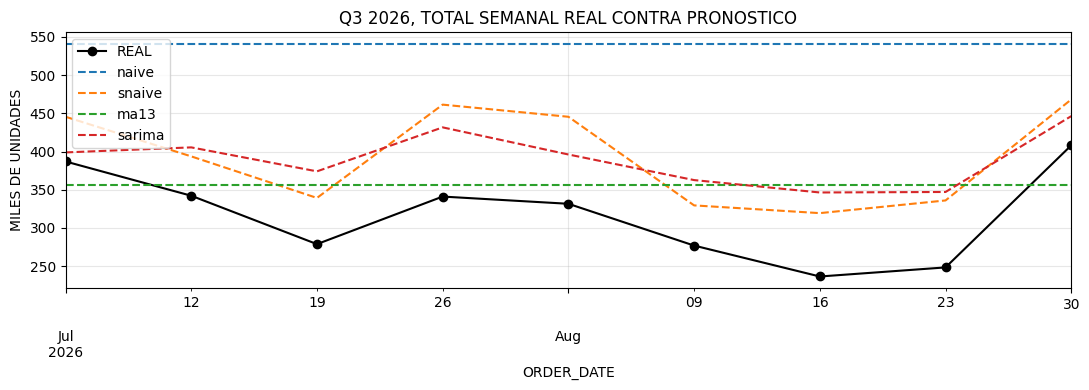

In [13]:
q3 = fc[fc.fold == 7]
real_q3 = q3.groupby(["DC_ID", "SKU_NBR"]).y.sum()
q3_2025 = fc[(fc.fold == 3) & (fc.h <= 9)].groupby(["DC_ID", "SKU_NBR"]).y.sum()       # mismas 9 semanas de 2025
comunes = real_q3.index.intersection(q3_2025.index)
print(f"CAIDA REAL FRENTE A 2025 EN LAS SERIES COMPARADAS {real_q3[comunes].sum() / q3_2025[comunes].sum() - 1:.1%}")

total = q3[["y"] + MODELOS_BASE].sum()
display(pd.DataFrame({"UNIDADES": total.round(0), "FRENTE AL REAL": (total / total["y"] - 1).round(3)}))

semanal = q3.groupby("ORDER_DATE")[["y"] + MODELOS_BASE].sum().rename(columns={"y": "REAL"}) / 1e3
ax = semanal.plot(figsize=(11, 4), style=["k-o"] + ["--"] * len(MODELOS_BASE))
ax.set_ylabel("MILES DE UNIDADES")
ax.set_title("Q3 2026, TOTAL SEMANAL REAL CONTRA PRONOSTICO")
plt.tight_layout()
plt.show()

## LECTURA DE Q3 DE 2026

RESULTADO: LAS 9 SEMANAS DE Q3 DE 2026 SUMAN 2,85 MILLONES DE UNIDADES, 18,5 POR CIENTO MENOS QUE LAS MISMAS SEMANAS DE 2025 CON TODAS LAS SERIES Y 20,5 POR CIENTO MENOS EN LAS SERIES QUE YA EXISTIAN EN 2025. TODOS LOS MODELOS SOBREPRONOSTICAN: NAIVE 70,8 POR CIENTO, NAIVE ESTACIONAL 24,1, SARIMA 23,1 Y MEDIA MOVIL 12,3. EN LA GRAFICA EL REAL QUEDA POR DEBAJO DEL SARIMA Y DEL NAIVE ESTACIONAL EN LA MAYORIA DE LAS SEMANAS.

EL NAIVE ESTACIONAL REPITE EL NIVEL DE 2025 Y EL SARIMA SOBREPRONOSTICA CASI IGUAL, LO QUE SUGIERE QUE EL SARIMA TAMBIEN SE ANCLA AL NIVEL HISTORICO Y NO AL NIVEL RECIENTE, ESTA EXPLICACION ES UNA HIPOTESIS Y NO SE PRUEBA EN ESTE PUNTO. LA MEDIA MOVIL REACCIONA MEJOR PORQUE SOLO USA LAS ULTIMAS 13 SEMANAS, PERO TAMPOCO ACIERTA Y NO TIENE ESTRUCTURA DE CALENDARIO.

POR ESO EL PUNTO 3 BUSCA MODELOS QUE COMBINEN EL CALENDARIO (FIN DE MES Y FIN DE TRIMESTRE) CON EL NIVEL RECIENTE DE CADA SERIE, SE EVALUARAN EN ESTOS MISMOS FOLDS Y CON ATENCION ESPECIAL AL FOLD PARCIAL.

## CIERRE DEL PUNTO 2

LA MEDIA MOVIL DE 13 SEMANAS ES EL METODO ACTUAL Y SE MANTIENE FIJA ANTES DE LA EVALUACION, NO SE ELIGE LA VENTANA MIRANDO LOS RESULTADOS DE PRUEBA, EL SARIMA USA UNA CONFIGURACION FIJA Y NO BUSCA ORDENES CON LOS DATOS DE PRUEBA.

RESULTADO: EN LOS SEIS TRIMESTRES COMPLETOS EL NAIVE ES EL PEOR (WAPE TRIMESTRAL EN SKU POR CD DE 58,4 POR CIENTO Y SESGO DE MAS 51,6) PORQUE REPITE LA SEMANA PICO DE CIERRE. EL NAIVE ESTACIONAL TIENE 39,9 POR CIENTO EN SKU POR CD, PERO ES EL MEJOR EN EL TOTAL (6,0 POR CIENTO TRIMESTRAL Y 10,3 SEMANAL). EL SARIMA MEJORA A LA MEDIA MOVIL EN EL WAPE SEMANAL (34,5 CONTRA 37,7 EN SKU POR CD) Y EN EL TRIMESTRAL DEL TOTAL (9,3 CONTRA 12,5), PERO NO EN SKU POR CD (25,4 CONTRA 24,6) NI EN SKU (21,8 CONTRA 21,9), Y NO SUPERA AL NAIVE ESTACIONAL EN EL TOTAL. EL SESGO ES DE MAS 5,7 PARA LA MEDIA MOVIL, MAS 9,1 PARA EL SARIMA Y MAS 3,1 PARA EL NAIVE ESTACIONAL.

EL BENCHMARK A SUPERAR EN EL PUNTO 3 ES LA MEDIA MOVIL DE 13 SEMANAS, CON WAPE TRIMESTRAL DE 24,6 POR CIENTO EN SKU POR CD, 21,9 EN SKU Y 12,5 EN EL TOTAL, EL NAIVE ESTACIONAL QUEDA COMO REFERENCIA ADICIONAL EN EL TOTAL.


### Punto 3

### Punto 4